In [1]:
# pandas is the main tool used throughout this notebook for loading and
# manipulating the Criteo dataset as a DataFrame.
import pandas as pd

In [2]:
# Load the raw Criteo uplift dataset (~14M rows). Each row is one user who
# was randomly assigned to either see an ad (treatment) or not (control).
df = pd.read_csv("../data/criteo-uplift-v2.1.csv")
df.shape

(13979592, 16)

In [3]:
# Peek at the raw rows: 12 anonymized numeric features (f0-f11), a treatment
# flag, and the outcome columns (conversion, visit, exposure).
df.head()

,f0,f1,f2,f3,f4,f5,f6,f7,f8,f9,f10,f11,treatment,conversion,visit,exposure
0,12.616365,10.059654,8.976429,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
1,12.616365,10.059654,9.002689,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
2,12.616365,10.059654,8.964775,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
3,12.616365,10.059654,9.002801,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
4,12.616365,10.059654,9.037999,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0


In [4]:
# Confirm the full set of columns we have to work with.
df.columns

Index(['f0', 'f1', 'f2', 'f3', 'f4', 'f5', 'f6', 'f7', 'f8', 'f9', 'f10',
       'f11', 'treatment', 'conversion', 'visit', 'exposure'],
      dtype='str')

In [5]:
# Randomization check: if treatment was assigned truly at random, treated and
# control users should look similar on average across all 12 features. Large
# differences here would suggest the "randomized" trial wasn't actually
# balanced, which would undermine any uplift estimate we compute later.
feature_cols = [f"f{i}" for i in range(12)]
df.groupby("treatment")[feature_cols].mean()

,f0,f1,f2,f3,f4,f5,f6,f7,f8,f9,f10,f11
treatment,,,,,,,,,,,,
0,19.651705,10.067935,8.448173,4.232821,10.336526,4.039339,-3.999880,5.080284,3.934652,15.886253,5.331898,-0.170868
1,19.614755,10.070337,8.446302,4.169412,10.339245,4.026602,-4.182792,5.105555,3.933392,16.052589,5.333660,-0.170985


In [6]:
# How many users are in each arm of the experiment.
df["treatment"].value_counts()

treatment
1    11882655
0     2096937
Name: count, dtype: int64

In [7]:
# Naive/observational conversion rate for the treated group across the whole
# dataset, no modeling involved yet — this is just a baseline sanity check.
treated_rate = df[df["treatment"] == 1]["conversion"].mean()
print(treated_rate)

0.0030894610674129645


In [8]:
# Same for the control group.
control_rate = df[df["treatment"] == 0]["conversion"].mean()
print(control_rate)

0.0019375880152813366


In [9]:
# Population-level average treatment effect (ATE) on conversion: the simple
# difference in rates, with no modeling. Named "naive" to distinguish it from
# the per-user model-based uplift score computed later in this notebook — the
# model's job is to refine this single population-wide number into a score
# that varies per individual, so we can target the users worth targeting.
naive_uplift = treated_rate - control_rate
print(naive_uplift)

0.0011518730521316279


In [10]:
# Same average-effect check, but on "visit" instead of "conversion" — does
# advertising also make people more likely to visit the site at all, not just
# buy something?
treated_visit_rate = df[df["treatment"] == 1]["visit"].mean()
control_visit_rate = df[df["treatment"] == 0]["visit"].mean()
uplift_visit = treated_visit_rate - control_visit_rate
print(treated_visit_rate, control_visit_rate, uplift_visit)

0.048543360048743316 0.03820095691954503 0.010342403129198284


In [11]:
# Check for missing values before modeling — none found, so no imputation
# strategy is needed.
df.isnull().sum()

f0            0
f1            0
f2            0
f3            0
f4            0
f5            0
f6            0
f7            0
f8            0
f9            0
f10           0
f11           0
treatment     0
conversion    0
visit         0
exposure      0
dtype: int64

In [12]:
# Summary statistics for all columns — useful for spotting outliers or
# unexpected ranges before feeding features into a model.
df.describe()

,f0,f1,f2,f3,f4,f5,f6,f7,f8,f9,f10,f11,treatment,conversion,visit,exposure
count,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07
mean,1.962030e+01,1.006998e+01,8.446582e+00,4.178923e+00,1.033884e+01,4.028513e+00,-4.155356e+00,5.101765e+00,3.933581e+00,1.602764e+01,5.333396e+00,-1.709672e-01,8.500001e-01,2.916680e-03,4.699200e-02,3.063122e-02
std,5.377464e+00,1.047557e-01,2.993161e-01,1.336645e+00,3.433081e-01,4.310974e-01,4.577914e+00,1.205248e+00,5.665958e-02,7.018975e+00,1.682288e-01,2.283277e-02,3.570713e-01,5.392748e-02,2.116217e-01,1.723164e-01
min,1.261636e+01,1.005965e+01,8.214383e+00,-8.398387e+00,1.028053e+01,-9.011892e+00,-3.142978e+01,4.833815e+00,3.635107e+00,1.319006e+01,5.300375e+00,-1.383941e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,1.261636e+01,1.005965e+01,8.214383e+00,4.679882e+00,1.028053e+01,4.115453e+00,-6.699321e+00,4.833815e+00,3.910792e+00,1.319006e+01,5.300375e+00,-1.686792e-01,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,2.192341e+01,1.005965e+01,8.214383e+00,4.679882e+00,1.028053e+01,4.115453e+00,-2.411115e+00,4.833815e+00,3.971858e+00,1.319006e+01,5.300375e+00,-1.686792e-01,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
75%,2.443646e+01,1.005965e+01,8.723335e+00,4.679882e+00,1.028053e+01,4.115453e+00,2.944427e-01,4.833815e+00,3.971858e+00,1.319006e+01,5.300375e+00,-1.686792e-01,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
max,2.674526e+01,1.634419e+01,9.051962e+00,4.679882e+00,2.112351e+01,4.115453e+00,2.944427e-01,1.199840e+01,3.971858e+00,7.529502e+01,6.473917e+00,-1.686792e-01,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00


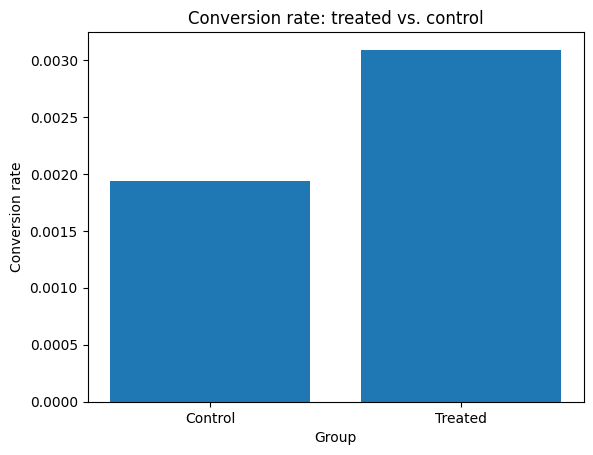

In [13]:
import matplotlib.pyplot as plt

# Chart 1: headline comparison — does the treated group convert more often
# than the control group?
plt.title("Conversion rate: treated vs. control")
plt.ylabel("Conversion rate")
plt.xlabel("Group")
plt.bar(["Control", "Treated"], [control_rate, treated_rate])

plt.savefig("../outputs/conversion_uplift.png", dpi=150, bbox_inches="tight")
plt.show()

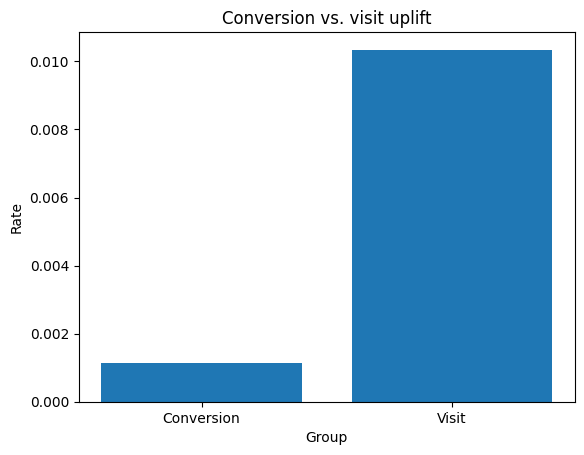

In [14]:
# Chart 2: compare the size of the treatment effect on conversion vs. visit.
plt.title("Conversion vs. visit uplift")
plt.xlabel("Group")
plt.ylabel("Rate")
plt.bar(["Conversion", "Visit"], [naive_uplift, uplift_visit])
plt.savefig("../outputs/conversionVsvisit.png", dpi=150, bbox_inches="tight")
plt.show()

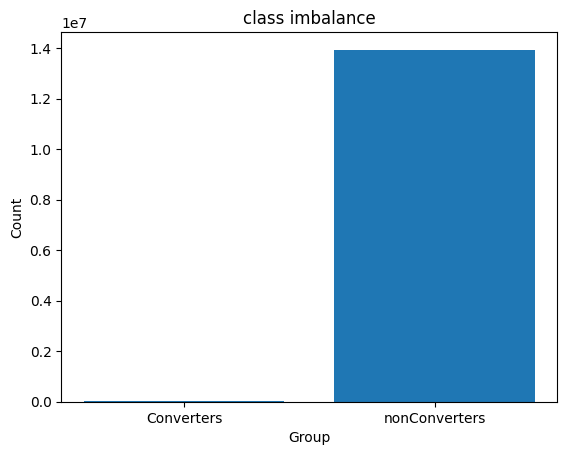

In [15]:
# Chart 3: class imbalance — conversions are rare events, which matters when
# choosing/evaluating a model later (plain accuracy would be a misleading
# metric here, since predicting "no conversion" for everyone would already
# score ~99.7%).
plt.title("class imbalance")
plt.xlabel("Group")
plt.ylabel("Count")
plt.bar(["Converters", "nonConverters"],
        [(df["conversion"] == 1).sum(), (df["conversion"] == 0).sum()])
plt.savefig("../outputs/class_imbalance.png", dpi=150, bbox_inches="tight")
plt.show()

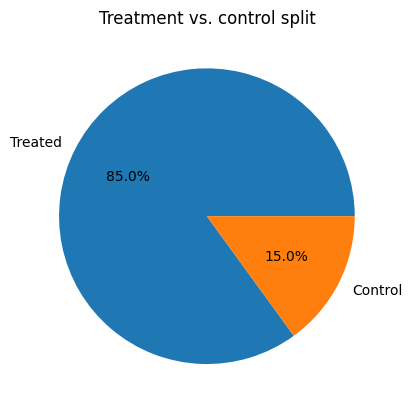

In [16]:
# Chart 4: visualize how small the control group is relative to treatment —
# this is the "cost" of running the experiment (users deliberately not shown
# ads, purely to have a baseline to compare against).
treated_count = (df["treatment"] == 1).sum()
control_count = (df["treatment"] == 0).sum()
plt.pie([treated_count, control_count],
        labels=["Treated", "Control"],
        autopct="%1.1f%%")
plt.title("Treatment vs. control split")
plt.savefig("../outputs/treatment_split.png", dpi=150, bbox_inches="tight")
plt.show()

# EDA Summary — Criteo Uplift Dataset

## Dataset overview
- 13,979,592 rows × 16 columns.
- Columns: 12 anonymized features (f0–f11), a treatment flag, and three
  outcome columns (conversion, visit, exposure).
- Data health: no missing values were found in any column, so no imputation
  was required.

## Treatment / control split
- Treated: 11,882,655 (85%) · Control: 2,096,937 (15%).
- The control group is kept deliberately small because withholding ads from
  users means giving up potential sales, so the advertiser holds back only
  enough people to form a reliable baseline for comparison.
- See: outputs/treatment_split.png

## Key finding 1 — Average treatment effect on conversion
- Control conversion rate: 0.00194 (0.194%)
- Treated conversion rate: 0.00309 (0.309%)
- Uplift: 0.00115 absolute, roughly a 60% relative increase.
- Advertising has a clear positive effect on average: users who could be shown
  an ad converted about 60% more often than those who

In [17]:
# The full dataset (~14M rows) is too large to iterate on quickly, so we work
# with a 7% sample from here on. We sample within each (treatment, conversion)
# group separately, rather than from the whole DataFrame at once, so the
# sample keeps the same treatment/control ratio (85/15) and the same (rare)
# conversion rate as the full population, instead of accidentally skewing
# either one.
sample_df = df.groupby(["treatment", "conversion"], group_keys=False).sample(
    frac=0.07, random_state=42
)

In [18]:
# Confirm the sample size is what we expect (~7% of ~14M rows).
sample_df.shape

(978571, 16)

In [19]:
# Confirm the treatment/control split ratio was preserved by the stratified
# sample (should still be ~85/15).
sample_df["treatment"].value_counts(normalize=True)

treatment
1    0.850001
0    0.149999
Name: proportion, dtype: float64

In [20]:
# Confirm conversions are still present, and still rare, in the sample.
sample_df["conversion"].value_counts()

conversion
0    975717
1      2854
Name: count, dtype: int64

In [21]:
# Hold out 20% of the sample as a test set. We stratify by (treatment,
# conversion) again for the same reason as above: a plain random split could,
# purely by chance, end up with very few converters in one arm, which would
# make the later Qini evaluation noisy.
from sklearn.model_selection import train_test_split

train_sample_df, test_sample_df = train_test_split(
    sample_df,
    test_size=0.2,
    random_state=42,
    stratify=sample_df[["treatment", "conversion"]]
)

In [22]:
# Sanity-check the split: sizes look right, and the treatment ratio is
# preserved in both train and test.
print(train_sample_df.shape, test_sample_df.shape)
print(train_sample_df["treatment"].value_counts(normalize=True))
print(test_sample_df["treatment"].value_counts(normalize=True))

(782856, 16) (195715, 16)
treatment
1    0.850001
0    0.149999
Name: proportion, dtype: float64
treatment
1    0.850001
0    0.149999
Name: proportion, dtype: float64


In [23]:
# NOTE: X_train / Y_train (the full training sample, treatment mixed in) are
# not actually used further down — the two-model approach below trains two
# separate models on the treated/control subsets instead (see the next few
# cells). Left in place since it doesn't affect any results; flag if you'd
# like these two lines removed.
features = [f"f{i}" for i in range(12)]
X_train = train_sample_df[features]
Y_train = train_sample_df["conversion"]

In [24]:
print(X_train.shape,Y_train.shape)


(782856, 12) (782856,)


In [25]:
# --- T-learner, model 1: trained ONLY on users who received treatment ---
treated = train_sample_df[train_sample_df["treatment"] == 1]
X_train_treated = treated[features]
y_train_treated = treated["conversion"]

In [26]:
# --- T-learner, model 2: trained ONLY on users who did NOT receive
# treatment (the control arm) ---
control = train_sample_df[train_sample_df["treatment"] == 0]
X_train_control = control[features]
y_train_control = control["conversion"]

In [27]:
# Treated group is much bigger than control (85/15 split), as expected.
print(X_train_treated.shape, X_train_control.shape)

(665428, 12) (117428, 12)


In [28]:
# Fit model 1: predicts P(conversion) for a user IF they are treated.
from sklearn.linear_model import LogisticRegression

model_treated = LogisticRegression(max_iter=1000)
model_treated.fit(X_train_treated, y_train_treated)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [29]:
# Fit model 2: predicts P(conversion) for a user IF they are NOT treated.
model_control = LogisticRegression(max_iter=1000)
model_control.fit(X_train_control, y_train_control)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [30]:
# Same feature columns, but from the held-out test set — neither model has
# seen these rows during training.
X_test = test_sample_df[features]

In [31]:
# Score every test user under both hypothetical scenarios: "what if they were
# treated?" vs. "what if they weren't?". predict_proba returns
# [P(class=0), P(class=1)], so column 1 is P(conversion=1).
p_treated = model_treated.predict_proba(X_test)[:, 1]
p_control = model_control.predict_proba(X_test)[:, 1]

In [32]:
# The T-learner's uplift score: the estimated Individual Treatment Effect
# (ITE) per user — how much treatment is predicted to change their conversion
# probability. This is the per-user score used to rank/target users, as
# opposed to the single population-wide naive_uplift computed earlier.
uplift = p_treated - p_control

In [33]:
print(uplift[:10])                 # first 10 users' individual uplift
print(uplift.mean())               # average across the test set
print(uplift.min(), uplift.max())  # the full range

[0.00043234 0.00011109 0.0009162  0.00017933 0.00011434 0.00010807
 0.00019423 0.00014746 0.00108834 0.00072385]
0.0009686512818683199
-0.001906923639165307 0.2709246436387698


In [34]:
# Ground-truth outcomes and treatment assignment for the test set — needed to
# evaluate the uplift model against what actually happened.
y_test = test_sample_df["conversion"]
treatment_test = test_sample_df["treatment"]

In [35]:
# Sanity check: all three arrays are aligned and the same length.
print(len(y_test), len(treatment_test), len(uplift))

195715 195715 195715


In [36]:
# scikit-uplift provides ready-made uplift evaluation metrics (Qini AUC,
# Qini curve) so we don't have to implement them by hand. Note:
# `sklift.viz.plot_qini_curve` is intentionally not imported here — in this
# environment it fails to import (a version mismatch with scikit-learn's
# internal check_matplotlib_support helper) and isn't needed anyway, since
# we build our own Qini plot manually further down.
from sklift.metrics import qini_auc_score, qini_curve

In [37]:
# Qini AUC: a single summary number for how well the model's uplift ranking
# concentrates real incremental conversions among the top-ranked users,
# compared to random targeting. Higher is better.
qini = qini_auc_score(y_test, uplift, treatment_test)
print(qini)

0.18660702585380523


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/utils/deprecation.py:95: FutureWarning: Function stable_cumsum is deprecated; `sklearn.utils.extmath.stable_cumsum` is deprecated in version 1.8 and will be removed in 1.10. Use `np.cumulative_sum` with the desired dtype directly instead.
  warnings.warn(msg, category=FutureWarning)


In [38]:
# Qini curve: cumulative incremental conversions as we target more and more
# users, ordered by predicted uplift (highest first).
x_actual, y_actual = qini_curve(y_test, uplift, treatment_test)

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/utils/deprecation.py:95: FutureWarning: Function stable_cumsum is deprecated; `sklearn.utils.extmath.stable_cumsum` is deprecated in version 1.8 and will be removed in 1.10. Use `np.cumulative_sum` with the desired dtype directly instead.
  warnings.warn(msg, category=FutureWarning)


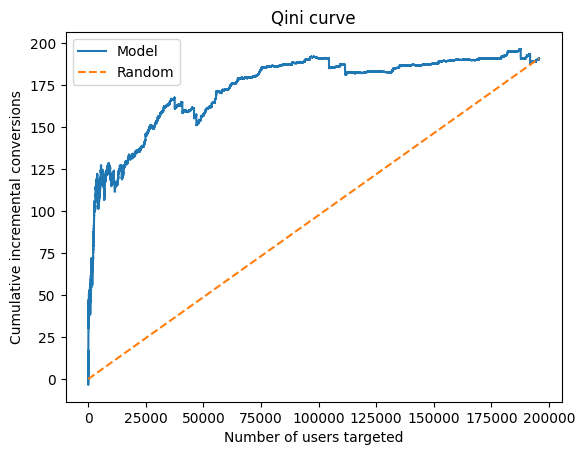

In [39]:
# Plot the model's Qini curve against the "random targeting" diagonal — the
# further the model's curve bows above the diagonal, the more value it adds
# over targeting users at random.
plt.plot(x_actual, y_actual, label="Model")
plt.xlabel("Number of users targeted")
plt.ylabel("Cumulative incremental conversions")
plt.title("Qini curve")
plt.plot([x_actual[0], x_actual[-1]], [y_actual[0], y_actual[-1]],
         linestyle="--", label="Random")
plt.legend()
plt.savefig("../outputs/qini_curve.png", dpi=150, bbox_inches="tight")
plt.show()

In [40]:
# Save per-user test-set results (ground truth + predicted uplift) so the
# Streamlit dashboard can load them without needing to retrain the model.
results = test_sample_df[["treatment", "conversion"]].copy()
results["uplift"] = uplift
results.to_csv("../outputs/uplift_results.csv", index=False)